In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

con = duckdb.connect("../dbt_project/fitness.duckdb", read_only=True)

def q(sql):
    """Run SQL against the dbt database and return a pandas DataFrame."""
    return con.sql(sql).df()

STRAVA, GARMIN = "#FC4C02", "#007CC3"   # brand colors for charts

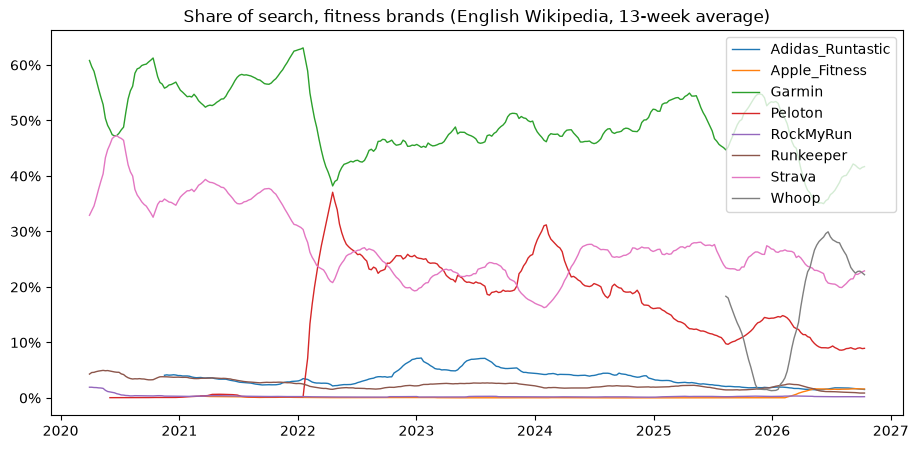

In [2]:
share = q("""
    select week_start, brand, share_of_search
    from fct_weekly_share_of_search
    where language = 'English'
      and week_start >= '2020-01-01'
      and week_start < date_trunc('week', current_date)   -- drop the incomplete current week
""")
share["week_start"] = pd.to_datetime(share["week_start"])

weekly = share.pivot(index="week_start", columns="brand", values="share_of_search")
smooth = weekly.rolling(13).mean()

fig, ax = plt.subplots(figsize=(11, 5))
for brand in smooth.columns:                       # all competitors in grey
    ax.plot(smooth.index, smooth[brand], lw=1, label=brand)
# ax.plot(smooth.index, smooth["Strava"], color=STRAVA, lw=2.5, label="Strava")
# ax.plot(smooth.index, smooth["Garmin"], color=GARMIN, lw=2.5, label="Garmin")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Share of search, fitness brands (English Wikipedia, 13-week average)")
ax.legend()
plt.show()

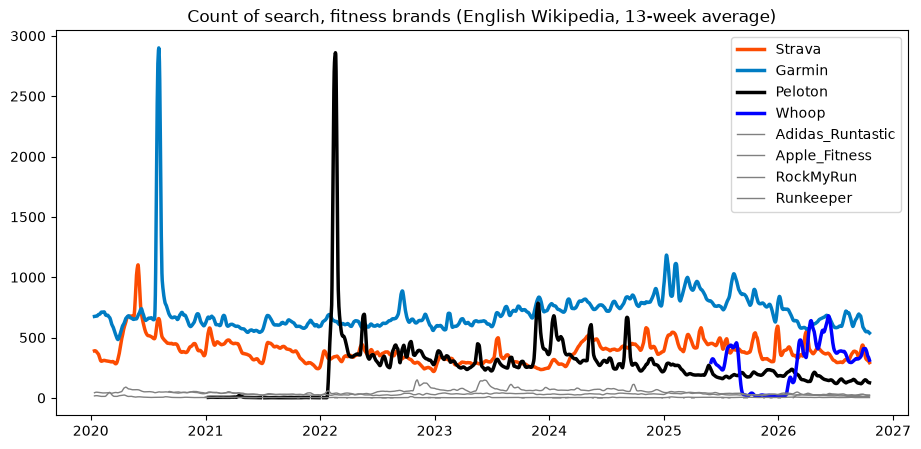

In [19]:
count = q("""
    select view_date, brand, views_7d_avg
    from fct_daily_brand_views
    where language = 'English'
      and article_type = 'brand'
      and view_date >= '2020-01-01'
      and view_date < date_trunc('week', current_date)   -- drop the incomplete current week
""")
count["view_date"] = pd.to_datetime(count["view_date"])

weekly = count.pivot(index="view_date", columns="brand", values="views_7d_avg")
smooth = weekly.rolling(13).mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(smooth.index, smooth["Strava"], color=STRAVA, lw=2.5, label="Strava")
ax.plot(smooth.index, smooth["Garmin"], color=GARMIN, lw=2.5, label="Garmin")
ax.plot(smooth.index, smooth["Peloton"], color="Black", lw=2.5, label="Peloton")
ax.plot(smooth.index, smooth["Whoop"], color="Blue", lw=2.5, label="Whoop")
for brand in smooth.columns: 
    if brand in ["Strava","Garmin","Peloton","Whoop"]:
        {}
    else: ax.plot(smooth.index, smooth[brand], color="Grey", lw=1, label=brand)# all other competitors in grey
ax.set_title("Count of search, fitness brands (English Wikipedia, 13-week average)")
ax.legend()
plt.show()

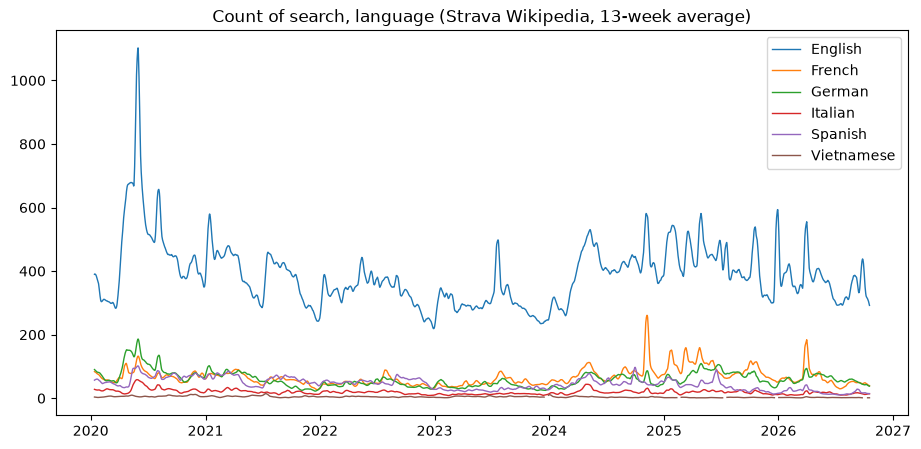

In [34]:
count_lang = q("""
    select 
    view_date, 
    language, 
    views_7d_avg,
    from fct_daily_brand_views
    where article_type = 'brand'
      and brand = 'Strava'
      and view_date >= '2020-01-01'
      and view_date < date_trunc('week', current_date)   -- drop the incomplete current week
""")
count["view_date"] = pd.to_datetime(count["view_date"])

weekly = count_lang.pivot(index="view_date", columns="language", values="views_7d_avg")
smooth = weekly.rolling(13).mean()

fig, ax = plt.subplots(figsize=(11, 5))
for language in smooth.columns: 
    ax.plot(smooth.index, smooth[language], lw=1, label=language)# all other competitors in grey
ax.set_title("Count of search, language (Strava Wikipedia, 13-week average)")
ax.legend()
plt.show()

#Next, rechart as a comparison to current day.

Visits in English remain around 400/day. Visits in French, German, and Italian grew starting around 2024, with a large increase particulary for French in 2025. Recengy, German has overtaken French as the language in the number 2 spot.

In [29]:
recentshare = share.filter(share['week_start']>="2025-01-01")
print(recentshare.head())

#I want to just look share of fivisits post Whoop launch - how do I do this?

Empty DataFrame
Columns: []
Index: [0, 1, 2, 3, 4]
Object `this` not found.


/var/folders/3y/ywdn2s3j6tn1kc0w67lm7d8h0000gn/T/ipykernel_54109/3398638865.py:1: UserWarning: A list-like of booleans passed positionally to DataFrame.filter selects labels. Pass cond=... to filter with a boolean mask, or items=... to select labels without this warning.
  recentshare = share.filter(share['week_start']>="2025-01-01")
